# 03 · Entrenamiento y comparación de modelos

**Proyecto:** Predicción de riesgo de burnout organizacional · **Autor:** Oscar Paúl Naranjo Castro
**Maestría en Inteligencia Artificial, UEES** · Todas las rutas son relativas a la raíz del repositorio.

Se comparan, con validación cruzada de 5 pliegues sobre train, un baseline trivial, un baseline de una sola variable, Ridge, SVR-RBF (réplica de Teodósio et al., 2025) y XGBoost con hiperparámetros por defecto.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
from sklearn.model_selection import KFold, cross_validate
from src.data_processing import FEATURES, clean_data, load_raw_data, split_data
from src.model import build_baselines, build_xgb_pipeline

df = clean_data(load_raw_data())
X_train, X_test, y_train, y_test = split_data(df, 0.2, 42)
cv = KFold(5, shuffle=True, random_state=42)
modelos = build_baselines(42)
modelos['XGBoost (por defecto)'] = build_xgb_pipeline(None, 42)

14:05:01 | INFO | src.data_processing | Datos cargados: 22750 filas, 9 columnas


14:05:01 | INFO | src.data_processing | Filas con objetivo observado: 21626 (se descartaron 1124)


In [3]:
filas = []
for nombre, m in modelos.items():
    r = cross_validate(m, X_train[FEATURES], y_train, cv=cv, return_train_score=True,
                       scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'})
    filas.append({'modelo': nombre,
                  'RMSE CV': -r['test_rmse'].mean(), 'DE RMSE': r['test_rmse'].std(),
                  'R2 CV': r['test_r2'].mean(), 'R2 train': r['train_r2'].mean(),
                  'segundos/pliegue': r['fit_time'].mean()})
cv_tab = pd.DataFrame(filas).set_index('modelo').sort_values('RMSE CV')
cv_tab.round(4)

,RMSE CV,DE RMSE,R2 CV,R2 train,segundos/pliegue
modelo,,,,,
SVR-RBF,0.0602,0.0002,0.9078,0.9116,4.5226
XGBoost (por defecto),0.0603,0.0004,0.9073,0.9225,0.0741
Ridge,0.0715,0.0006,0.8697,0.8699,0.0201
Solo fatiga (lineal),0.0866,0.0011,0.8090,0.8091,0.0059
Media (sin modelo),0.1981,0.0013,-0.0004,0.0000,0.0063


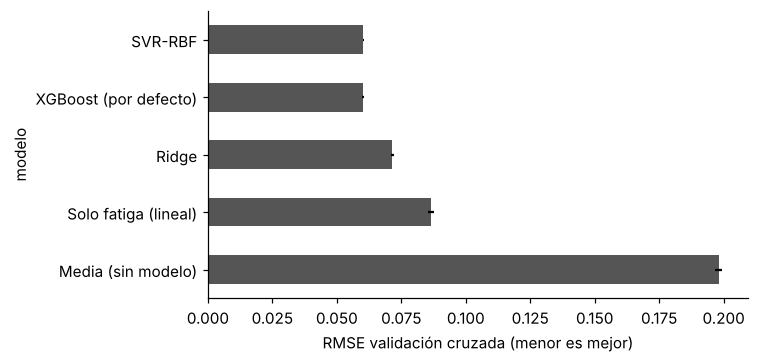

In [4]:
ax = cv_tab['RMSE CV'].sort_values().plot(kind='barh', xerr=cv_tab['DE RMSE'], color='#555', figsize=(7, 3.4))
ax.invert_yaxis(); ax.set_xlabel('RMSE validación cruzada (menor es mejor)')
plt.tight_layout(); plt.savefig(FIG / 'cv_model_comparison.png', dpi=150); plt.show()

**Lectura.**
* El baseline exigido de una sola variable (fatiga) explica cerca del 81 % de la varianza: es un listón alto.
* XGBoost y SVR-RBF empatan prácticamente en error; Ridge queda atrás porque la relación no es del todo lineal.
* La diferencia entre R² de train y de validación es pequeña en XGBoost: no hay sobreajuste relevante.

**Selección: XGBoost.** Con error equivalente al SVR, XGBoost entrena en una fracción del tiempo, maneja la
multicolinealidad, permite explicaciones exactas con TreeSHAP y escala mejor para la aplicación.

## Efecto del indicador de dato faltante

In [5]:
from sklearn.model_selection import cross_val_predict
res = {}
for flag in [False, True]:
    p = cross_val_predict(build_xgb_pipeline(None, 42, add_missing_indicator=flag), X_train[FEATURES], y_train, cv=cv)
    imp = X_train['Mental Fatigue Score'].isna()
    res['Con indicador' if flag else 'Sin indicador'] = {
        'RMSE total': np.sqrt(np.mean((y_train - p) ** 2)),
        'RMSE fatiga imputada': np.sqrt(np.mean((y_train[imp] - p[imp]) ** 2)),
        'RMSE fatiga observada': np.sqrt(np.mean((y_train[~imp] - p[~imp]) ** 2))}
pd.DataFrame(res).T.round(4)

,RMSE total,RMSE fatiga imputada,RMSE fatiga observada
Sin indicador,0.0615,0.1048,0.0555
Con indicador,0.0603,0.1017,0.0546


El indicador permite al modelo tratar distinto los casos sin fatiga y reduce su error sin perjudicar al resto; por eso se incorpora al modelo final como mitigación de equidad.